Starting H6 Macro Simulation: Coefficient Contamination...
Spectrum Features (D) = 100, Target sample sizes = [1000, 10000, 100000, 1000000, 5000000, 10000000]

--- Running for N = 1,000 ---
  Log-Log Pearson Correlation (p vs Beta) = -0.3585 (MCSE: 0.0422)

--- Running for N = 10,000 ---
  Log-Log Pearson Correlation (p vs Beta) = -0.6639 (MCSE: 0.0122)

--- Running for N = 100,000 ---
  Log-Log Pearson Correlation (p vs Beta) = -0.9515 (MCSE: 0.0084)

--- Running for N = 1,000,000 ---
  Log-Log Pearson Correlation (p vs Beta) = -0.9952 (MCSE: 0.0004)

--- Running for N = 5,000,000 ---
  Log-Log Pearson Correlation (p vs Beta) = -0.9980 (MCSE: 0.0001)

--- Running for N = 10,000,000 ---
  Log-Log Pearson Correlation (p vs Beta) = -0.9986 (MCSE: 0.0001)


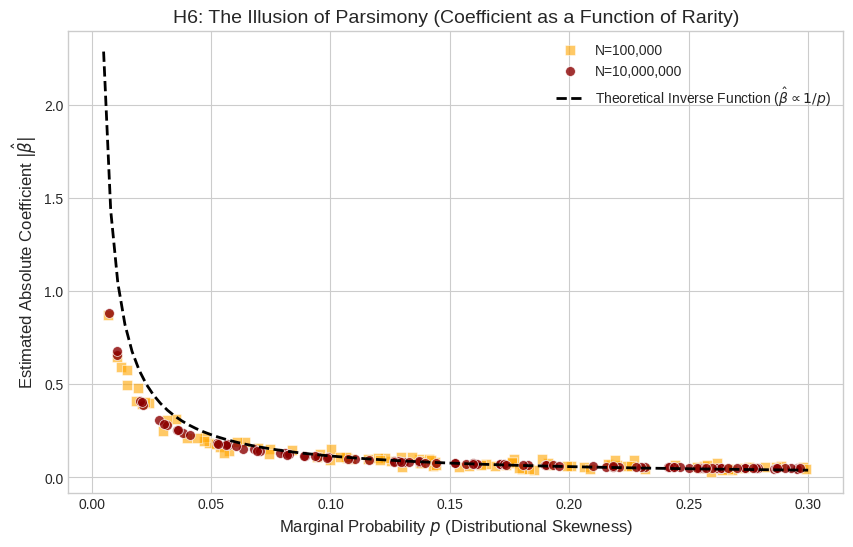

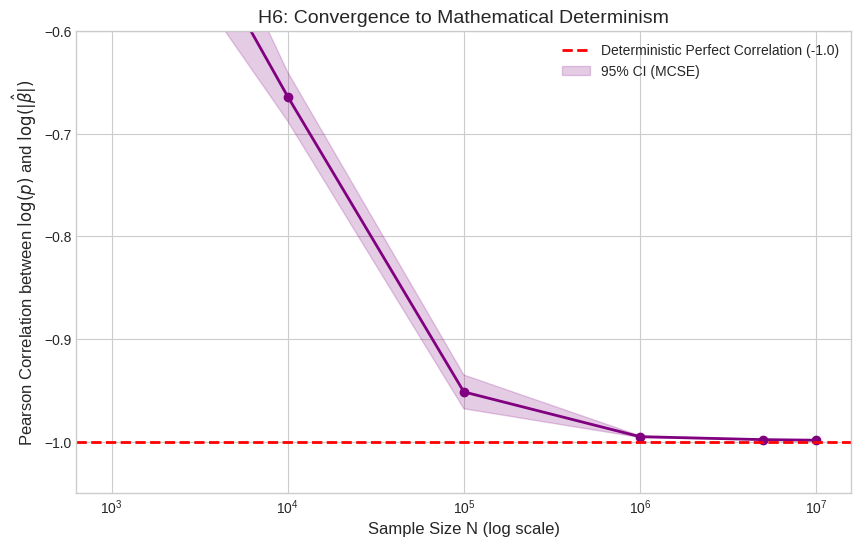


All calculations completed successfully. Generating H6_Simulation_Results.zip...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from scipy.stats import pearsonr
import warnings
import os
import zipfile
import gc
from google.colab import files

# ==========================================
# H6: Coefficient Contamination via Distributional Skewness
# ==========================================
warnings.filterwarnings("ignore")

output_dir = "h6_simulation_results"
os.makedirs(output_dir, exist_ok=True)

# シミュレーション設定
N_list = [1000, 10000, 100000, 1000000, 5000000, 10000000]
D = 100  # 異なる偏り(p)を持つノイズ変数の数（スペクトラム解析用）
T = 5    # MCSE用試行回数
spurious_bias = 0.01  # H4/H5同様の微小な測定アーティファクト(1%)

results_summary = []
scatter_data = []

print("Starting H6 Macro Simulation: Coefficient Contamination...")
print(f"Spectrum Features (D) = {D}, Target sample sizes = {N_list}")

for N in N_list:
    print(f"\n--- Running for N = {N:,} ---")
    trial_corrs = []

    for t in range(T):
        # 1. 目的変数の生成 (真の因果関係はゼロ)
        y = np.random.binomial(1, 0.5, N).astype(np.int8)

        # 2. 初期値依存性を排除した偏りスペクトラムの生成
        # pを 0.5% (極端な偏り) から 30% (穏やかな偏り) まで一様生成
        p_base = np.random.uniform(0.005, 0.3, D)

        betas = []

        # メモリセーフな逐次評価
        for j in range(D):
            # 1%の微小な疑似相関（測定バイアス）を付与
            prob_x = np.clip(p_base[j] + spurious_bias * y, 0, 1)
            X_j = np.random.binomial(1, prob_x).astype(np.int8)

            # ペナルティなしロジスティック回帰で係数を推定
            clf = LogisticRegression(penalty=None, solver='lbfgs')
            clf.fit(X_j.reshape(-1, 1), y)
            beta = np.abs(clf.coef_[0][0])
            betas.append(beta)

            # 散布図用データの保存 (最後の試行のみグラフ化用に全N保存)
            if t == T - 1:
                scatter_data.append({
                    'Sample_Size_N': N,
                    'Marginal_Prob_p': p_base[j],
                    'Absolute_Beta': beta
                })

            del X_j

        gc.collect()

        # 3. 係数の大きさと偏りの相関を評価 (対数スケールでのピアソン相関)
        # 理論上、beta ∝ 1/p であるため、log(beta) と log(p) の相関は -1.0 に収束する
        log_p = np.log(p_base)
        log_beta = np.log(betas)
        corr, _ = pearsonr(log_p, log_beta)
        trial_corrs.append(corr)

    # 統計量の計算
    mean_corr = np.mean(trial_corrs)
    mcse_corr = np.std(trial_corrs) / np.sqrt(T)

    print(f"  Log-Log Pearson Correlation (p vs Beta) = {mean_corr:.4f} (MCSE: {mcse_corr:.4f})")

    results_summary.append({
        'Sample_Size_N': N,
        'Mean_Correlation': mean_corr,
        'MCSE_Correlation': mcse_corr
    })

# DataFrame化して保存
df_summary = pd.DataFrame(results_summary)
df_summary.to_csv(f"{output_dir}/h6_summary_metrics.csv", index=False)

df_scatter = pd.DataFrame(scatter_data)
df_scatter.to_csv(f"{output_dir}/h6_scatter_data.csv", index=False)

# ==========================================
# グラフの描画と保存
# ==========================================
plt.style.use('seaborn-v0_8-whitegrid')

# 1. 係数と偏りの決定論的関係（散布図: 1/p の曲線）
plt.figure(figsize=(10, 6))
# 代表として N=1000万 と N=10万 のデータをプロット
df_scatter_10M = df_scatter[df_scatter['Sample_Size_N'] == 10000000]
df_scatter_100K = df_scatter[df_scatter['Sample_Size_N'] == 100000]

sns.scatterplot(data=df_scatter_100K, x='Marginal_Prob_p', y='Absolute_Beta',
                color='orange', label=f'N=100,000', alpha=0.6, s=50, marker='s')
sns.scatterplot(data=df_scatter_10M, x='Marginal_Prob_p', y='Absolute_Beta',
                color='darkred', label=f'N=10,000,000', alpha=0.8, s=50)

# 理論曲線 (y = c / x) のフィッティング線をイメージとして追加
x_vals = np.linspace(0.005, 0.3, 100)
c_10M = (df_scatter_10M['Absolute_Beta'] * df_scatter_10M['Marginal_Prob_p']).mean()
plt.plot(x_vals, c_10M / x_vals, color='black', linestyle='--', linewidth=2, label=r'Theoretical Inverse Function ($\hat{\beta} \propto 1/p$)')

plt.xlabel('Marginal Probability $p$ (Distributional Skewness)', fontsize=12)
plt.ylabel(r'Estimated Absolute Coefficient $|\hat{\beta}|$', fontsize=12)
plt.title('H6: The Illusion of Parsimony (Coefficient as a Function of Rarity)', fontsize=14)
plt.legend(fontsize=10)
plt.savefig(f"{output_dir}/fig1_beta_vs_skewness.png", dpi=300, bbox_inches='tight')
plt.show()

# 2. 相関係数の-1.0への決定論的収束
plt.figure(figsize=(10, 6))
plt.plot(df_summary['Sample_Size_N'], df_summary['Mean_Correlation'],
         marker='o', color='purple', linewidth=2)
plt.axhline(y=-1.0, color='red', linestyle='--', linewidth=2, label='Deterministic Perfect Correlation (-1.0)')

plt.fill_between(df_summary['Sample_Size_N'],
                 df_summary['Mean_Correlation'] - 1.96 * df_summary['MCSE_Correlation'],
                 df_summary['Mean_Correlation'] + 1.96 * df_summary['MCSE_Correlation'],
                 color='purple', alpha=0.2, label='95% CI (MCSE)')

plt.xscale('log')
plt.ylim(-1.05, -0.6)
plt.xlabel('Sample Size N (log scale)', fontsize=12)
plt.ylabel(r'Pearson Correlation between $\log(p)$ and $\log(|\hat{\beta}|)$', fontsize=12)
plt.title('H6: Convergence to Mathematical Determinism', fontsize=14)
plt.legend(fontsize=10)
plt.savefig(f"{output_dir}/fig2_correlation_convergence.png", dpi=300, bbox_inches='tight')
plt.show()

# ZIP圧縮
zip_filename = "H6_Simulation_Results.zip"
with zipfile.ZipFile(zip_filename, 'w') as zipf:
    for root, dirs, files_list in os.walk(output_dir):
        for file in files_list:
            zipf.write(os.path.join(root, file), arcname=file)

print(f"\nAll calculations completed successfully. Generating {zip_filename}...")
files.download(zip_filename)